# 소비 인텔리전스 2단계 · 이번 달 지출 예측

**질문**: 이번 달 c일까지의 가계부만 보고, 이번 달에 모두 얼마를 쓸까?

> ⚠️ **합성 데이터**(가상의 세 사람)로 만든 결과다. 숫자는 방법을 비교하려는 용도이며 실제 사람들의 예측 성능이 아니다.

진행 순서: 데이터셋 만들기 → (누수 발견과 수정) → 기준 모델 vs 머신러닝 비교 → 처음 보는 사람 검증 → 변수 중요도 → 예산 초과 가능성 → 이상 패턴 탐지 비교 → 결론

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path("analysis")
sys.path.insert(0, str(ROOT / "python"))
import forecast as F
plt.rcParams["font.family"] = "Malgun Gothic"; plt.rcParams["axes.unicode_minus"] = False
tx, fixed, budgets, as_of = F.load()
df = F.build_dataset(tx, fixed, as_of)
print("예측 문제 줄 수", len(df), "· 사람", df.user_id.nunique(), "· 달", df.month.nunique())
df.head(3)[["user_id", "month", "c", "to_date", "rate28", "prev3_avg", "fixed_remaining", "target"]]

예측 문제 줄 수 882 · 사람 3 · 달 10


,user_id,month,c,to_date,rate28,prev3_avg,fixed_remaining,target
0,u_junior,2026-01,1,467200.0,24233.928571,1246550.0,70000,1265350.0
1,u_junior,2026-01,2,487400.0,22441.071429,1246550.0,70000,1265350.0
2,u_junior,2026-01,3,521700.0,21712.500000,1246550.0,70000,1265350.0


## 1. 미래 정보 누수를 찾고 고친 기록

처음 만든 '지난달 쓴 돈' 특징은 날짜 오프셋(`prev_end - MonthBegin(0)`)으로 계산했는데, 이게 **이번 달 1일**로 넘어가
**이번 달 정답(target)이 그대로 특징에 들어갔다**. 그 결과 Ridge의 검증 MAE가 8,553원(1.3%)으로 비현실적으로 작았다.

'너무 좋은 결과'를 의심해 `지난달 쓴 돈 − 정답`을 직접 비교해 보니 **차이가 0원**이었다. 달 번호(Period)로 명시적으로 계산하도록 고쳤고,
지금은 아래처럼 지난달 값이 정답과 다르다(정상).

In [2]:
g = df.groupby(["user_id", "month"]).agg(정답=("target", "first"), 지난달=("prev_total", "first")).reset_index()
print("지난달 값과 정답의 평균 차이:", round((g.지난달 - g.정답).abs().mean()), "원  (0이면 누수)")
g.tail(4)

지난달 값과 정답의 평균 차이: 117148 원  (0이면 누수)


,user_id,month,정답,지난달
26,u_student,2026-07,414550.0,630600.0
27,u_student,2026-08,439850.0,414550.0
28,u_student,2026-09,774550.0,439850.0
29,u_student,2026-10,785250.0,774550.0


## 2. 모델 비교 (시간 순서 검증)

학습: 2026-01 ~ 2026-06 · 검증: 2026-07 ~ 2026-10. 같은 달을 학습과 검증에 나눠 넣지 않는다.

| 모델 | 방법 |
| --- | --- |
| B1 진행 속도 | 지금까지 변동비 ÷ 지난 날 × 남은 날 + 남은 고정비 |
| B2 최근 3달 평균 | 이번 달 기록을 보지 않고 지난 3달 평균 |
| B3 최근 28일 속도 | 지금까지 쓴 돈 + 최근 28일 하루 평균 변동비 × 남은 날 + 남은 고정비 |
| **B4 혼합** | 지난 날 비율만큼 B3, 남은 날 비율만큼 B2를 섞음 |
| Ridge · XGBoost | 15개 특징으로 월말 쓴 돈을 학습 |

In [3]:
scores, imp, test, info = F.evaluate(df)
print(info)
scores

{'train_rows': 525, 'test_rows': 357, 'train_months': ['2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06'], 'test_months': ['2026-07', '2026-08', '2026-09', '2026-10']}


,모델,MAE(원),MAPE(%),MAE 1~10일,MAE 11~20일,MAE 21일~
0,B1_진행속도,145564,15.2,278831,115806,39403
1,B2_최근3달평균,161679,22.2,161796,161796,161439
2,B3_최근28일속도,86235,10.9,137171,84531,35739
3,B4_혼합,83776,12.2,137008,83187,29782
4,Ridge,101354,15.6,121105,101370,81079
5,XGBoost,109963,14.1,122500,104796,102402


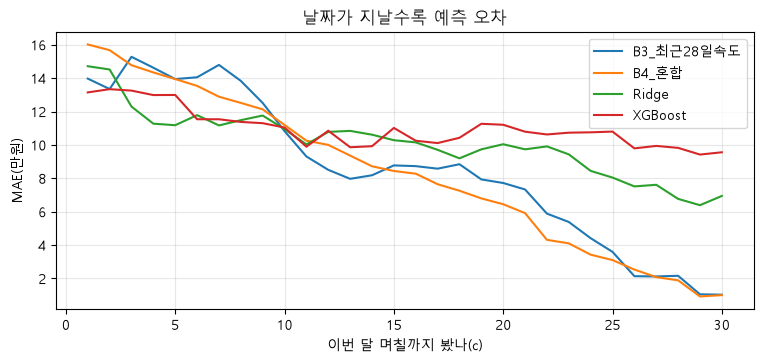

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for m in ["B3_최근28일속도", "B4_혼합", "Ridge", "XGBoost"]:
    ax.plot(test.groupby("c").apply(lambda s: (s[m] - s.target).abs().mean() / 1e4), label=m)
ax.set_xlabel("이번 달 며칠까지 봤나(c)"); ax.set_ylabel("MAE(만원)"); ax.set_title("날짜가 지날수록 예측 오차"); ax.legend(); ax.grid(alpha=.3)
plt.show()

**해석**: 단순한 B4·B3가 Ridge·XGBoost보다 오차가 작다. 학습할 수 있는 '달'이 사람당 6개뿐이라 복잡한 모델이 배울 것이 적다.
달 후반(21일~)에는 이미 쓴 돈이 대부분이라 B3·B4의 오차가 크게 줄어든다.

## 3. 처음 보는 사람에게도 통할까? (한 사람을 빼고 학습)
실제 앱에서는 새 사용자가 계속 들어온다. 두 사람으로 학습하고 남은 한 사람으로 검증한다.

In [5]:
F.evaluate_new_user(df)

검증한 사람,모델,특징,u_junior,u_saver,u_student,평균
0,B3_최근28일속도,-,126140.0,86042.0,46522.0,86235.0
1,B4_혼합,-,77285.0,74641.0,99401.0,83776.0
2,Ridge,고정비 합계 뺌,1939163.0,144996.0,123476.0,735878.0
3,Ridge,전체 특징,3248503.0,254700.0,312143.0,1271782.0
4,XGBoost,고정비 합계 뺌,864231.0,191522.0,172749.0,409501.0
5,XGBoost,전체 특징,896153.0,185495.0,156321.0,412656.0


**해석**: Ridge·XGBoost는 처음 보는 사람에서 크게 틀린다. 사람마다 고정비·소비 수준이 달라, 두 사람으로 배운 관계가 세 번째 사람에게 맞지 않기 때문이다.
B3·B4는 '그 사람 자신의 최근 기록'만 쓰므로 새 사람에게도 같은 방식으로 동작한다 → **앱에는 B4(3달 기록이 없으면 B3)를 쓴다.**

## 4. 변수 중요도 (원인이 아니다)

- XGBoost gain: 나무를 나눌 때 그 변수로 오차를 얼마나 줄였는지의 비율
- 순열 중요도: 검증 데이터에서 그 변수를 뒤섞었을 때 MAE가 얼마나 늘었는지

⚠️ 중요도는 '예측에 많이 쓰였다'는 뜻일 뿐 '그 변수 때문에 지출이 늘었다'는 인과가 아니다.
여기서 1위인 `fixed_month`(한 달 고정비 합계)는 사람마다 달라 사실상 **'누구인지'를 알려 주는 신호**로 쓰였다.

In [6]:
imp

,feature,xgb_gain_share,permutation_mae_increase
6,fixed_month,0.930,225247.0
10,prev_total,0.030,31256.0
13,weekend_rate28,0.011,13956.0
9,rate56,0.001,5922.0
8,rate28,0.005,5619.0
14,weekday_rate28,0.004,5501.0
11,prev3_avg,0.014,3280.0
7,rate7,0.002,1754.0
5,fixed_remaining,0.000,267.0
3,to_date,0.000,250.0


## 5. 예산 초과 가능성
최근 84일에서 '남은 날 수만큼 이어진 기간'들의 변동비 합을 하나씩 대입해, 예산을 넘는 경우의 비율을 센다(같은 입력이면 늘 같은 값 → 앱과 똑같이 계산 가능). 검증 달 15일 시점의 확률을 실제 초과 여부와 비교한다(Brier 점수: 0에 가까울수록 좋음).

In [7]:
ov = F.eval_overrun(tx, fixed, budgets, as_of)
base = ov.actual_over.mean()
print("Brier 점수", round(ov.attrs["brier"], 4), "· 비교: 늘 같은 확률(초과 비율", round(base, 2), ")을 말할 때", round(((base - ov.actual_over) ** 2).mean(), 4))
ov

Brier 점수 0.1221 · 비교: 늘 같은 확률(초과 비율 0.25 )을 말할 때 0.1875


,user_id,month,prob_over,actual_over,budget,actual
0,u_student,2026-07,0.0000,0,590000,345650
1,u_student,2026-08,0.0000,0,590000,385650
2,u_student,2026-09,0.6000,1,590000,705650
3,u_student,2026-10,0.6232,1,590000,716350
4,u_junior,2026-07,0.0000,0,1330000,747350
5,u_junior,2026-08,0.2464,0,1330000,1098100
6,u_junior,2026-09,0.0000,0,1330000,674400
7,u_junior,2026-10,0.0000,0,1330000,711600
8,u_saver,2026-07,0.0580,0,430000,219950
9,u_saver,2026-08,0.0000,1,430000,522200


## 6. 이상 패턴 탐지: 규칙 vs IsolationForest
1단계의 규칙(P95×2)과 비지도 머신러닝(IsolationForest)을 같은 정답표(일부러 넣은 5건)로 비교한다.

In [8]:
from sklearn.ensemble import IsolationForest
truth = pd.read_csv(ROOT / "data" / "anomalies_truth.csv")
s = tx[tx.kind.eq("spend")].copy()
s["log_amount"] = np.log(s.amount)
s["cat_ratio"] = s.amount / s.groupby(["user_id", "cat"]).amount.transform("median")
s["merchant_ratio"] = s.amount / s.groupby(["user_id", "merchant"]).amount.transform("median")
rows = []
for k in [5, 10, 20]:
    iso = IsolationForest(n_estimators=300, random_state=0, contamination="auto").fit(s[["log_amount", "cat_ratio", "merchant_ratio"]])
    sc = -iso.score_samples(s[["log_amount", "cat_ratio", "merchant_ratio"]])
    top = s.assign(score=sc).sort_values("score", ascending=False).head(k)
    hit = top.id.isin(truth.id).sum()
    rows.append({"방법": f"IsolationForest 상위 {k}건", "잡은 수": k, "맞힘": hit, "정밀도": round(hit / k, 2), "재현율": round(hit / len(truth), 2)})
rule = pd.read_csv(ROOT / "results" / "06_anomaly.csv")
hit = rule.id.isin(truth.id).sum()
rows.append({"방법": "규칙 P95×2 (앱)", "잡은 수": len(rule), "맞힘": hit, "정밀도": round(hit / len(rule), 2), "재현율": round(hit / len(truth), 2)})
pd.DataFrame(rows)

,방법,잡은 수,맞힘,정밀도,재현율
0,IsolationForest 상위 5건,5,5,1.00,1.0
1,IsolationForest 상위 10건,10,5,0.50,1.0
2,IsolationForest 상위 20건,20,5,0.25,1.0
3,규칙 P95×2 (앱),7,4,0.57,0.8


**해석**: 숫자만 보면 IsolationForest(상위 5건)가 정답 5건을 모두 맞혀 규칙보다 좋다. 하지만 공정한 비교가 아니다.
- 특징(분류·가게별 중앙값)을 **전체 기간**으로 계산해서, 그 거래 **이후**의 기록까지 기준에 들어갔다(나중에 돌아보는 분석이라 가능). 앱은 지출이 생긴 그날 알려야 해서 그 이후 기록을 쓸 수 없다.
- '상위 몇 건'을 고르려면 이상 지출이 몇 건인지 미리 알아야 한다(여기선 정답이 5건인 걸 알아서 5로 잘랐다). 10건·20건으로 늘리면 정밀도가 0.5·0.25로 떨어진다.
- 규칙은 그 거래 **전날까지의 기록만** 쓰고, '평소의 몇 배'처럼 이유를 말할 수 있어 앱 알림에 맞다.
→ 앱은 규칙을 쓰고, IsolationForest는 '지난 기록을 돌아보는 월간 리포트'에 쓸 수 있는 후보로 남긴다.

## 7. 결론과 한계
- 앱의 월말 예상: **B4 혼합**(3달 기록이 없으면 B3). 검증 MAE가 가장 작고, 사람마다 따로 계산돼 새 사용자에게도 같은 방식으로 동작하며, 계산 과정을 말로 설명할 수 있다.
- 머신러닝(Ridge·XGBoost)은 이 데이터 크기에서 기준 모델을 이기지 못했다. 실제 사용자 데이터가 동의를 받아 충분히 모이면 같은 코드로 다시 비교한다.
- 누수를 한 번 겪었다: 결과가 지나치게 좋으면 특징과 정답을 직접 비교해 본다.
- 합성 데이터는 실제보다 규칙적이다. 실제 데이터에서는 오차가 더 클 수 있다.